# DS101 Lecture 02: Data, EDA and Pharma

**From transaction records to meaningful customer features.**

This notebook follows the Lecture 02 slides one section at a time. Every section has:

- **Why**: the idea from the slide and why it matters.
- **Code**: run it and look at the output (outputs are already saved, so you can compare).
- **Reading the output**: what the result shows and what it does *not* show.
- **Check yourself**: a short question. Click *Answer* only after you have thought about it.

The **Homework** tasks are at the end.

> **About the data.** This is a *synthetic teaching fixture*: fictional business accounts buying
> products from a catalog. It is **not** the historical Pharma dataset. It contains no patients and
> has no clinical meaning. All numbers come from `data/transactions_raw.csv`, generated by
> `prepare_l02.py` with a fixed seed. Every account's R, F and M equals the values plotted on the
> slides, so the tables and plots below match the deck, except the t-SNE maps and the learned
> vectors, which are recomputed (see `README.md`).

### Learning goals (slide 2)

| Step | Question |
|---|---|
| 1. Inspect | What does each row mean? |
| 2. Represent | How do records become features? |
| 3. Explore | Which patterns depend on our choices? |
| 4. Interpret | What can the evidence support? |

*A pattern is a starting point, not a conclusion.*

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import CountVectorizer

DATA = Path("data")
WINDOW_START = pd.Timestamp("2026-01-01")
SNAPSHOT = pd.Timestamp("2026-04-01")  # observation window: 1 Jan - 31 Mar 2026
RFM_COLS = ["recency_days", "frequency_orders", "monetary_net_cu"]
POINT = "#176493"                                           # slide color for unlabeled points
COLORS = {"C1": "#176493", "C2": "#167C85", "C3": "#7056C2"}  # slide colors per cluster
MARKERS = {"C1": "o", "C2": "D", "C3": "^"}                 # slide symbols: circle, diamond, triangle
TSNE_SETTINGS = dict(n_components=2, init="pca", learning_rate="auto", max_iter=1200)

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 90

## 1. Inspect: what is actually in this dataset? (slide 3)

**Why.** Before transforming anything, check what one row means, which columns identify a record,
what types the columns have, what is missing and what the value ranges are. Every later step builds
on these facts. The raw file is **never overwritten**: we read it, and every cleaning step creates a
new table.

In [2]:
raw = pd.read_csv(DATA / "transactions_raw.csv")
print("shape:", raw.shape)
raw.head(8)

shape: (1109, 7)


,line_id,account_id,order_id,order_date,product_id,event_type,line_value_cu
0,L0001,A001,O001,2026-01-10,P03,purchase,100.00
1,L0002,A001,O002,2026-02-20,P07,purchase,150.00
2,L0003,A001,O002,2026-02-20,P12,purchase,50.00
3,L0004,A001,O003,2026-03-22,P05,purchase,200.00
4,L0005,A001,C001,2026-03-25,P05,credit,-40.00
5,L0006,A002,O004,2026-01-01,P10,purchase,34.15
6,L0007,A002,O005,2026-01-11,P11,purchase,34.18
7,L0008,A002,O005,2026-01-11,P14,purchase,204.71


**Reading the output.** 1,109 rows and 7 columns. One row is **one product line** of an order, or a
credit note. Account `A001` has two rows with order `O002`: one order with two different products.

In [3]:
raw.dtypes

line_id              str
account_id           str
order_id             str
order_date           str
product_id           str
event_type           str
line_value_cu    float64
dtype: object

**Reading the output.** `order_date` is read as text (`object` in pandas 2, `str` in pandas 3), not as a date. pandas does not parse
dates unless we ask it to, so we will parse them ourselves and check which ones fail.

In [4]:
print("repeated line_id :", raw["line_id"].duplicated().sum())
print("repeated order_id:", raw["order_id"].duplicated().sum())
print()
print("missing values per column:")
print(raw.isna().sum())

repeated line_id : 1
repeated order_id: 539

missing values per column:
line_id          0
account_id       0
order_id         0
order_date       0
product_id       0
event_type       0
line_value_cu    0
dtype: int64


**Reading the output.** Only **one** `line_id` repeats, but hundreds of `order_id` values repeat.
*A repeated order is not necessarily a repeated row*: an order with three products has three lines.
The identifier that should be unique is `line_id`. No column has missing values (`NaN`), but that does
not mean every value is valid, as the next section shows.

In [5]:
raw["line_value_cu"].describe()

count    1109.000000
mean      151.542543
std       127.537685
min      -314.700000
25%        62.370000
50%       121.400000
75%       208.280000
max       986.740000
Name: line_value_cu, dtype: float64

In [6]:
# NumPy array vs pandas DataFrame
values = raw["line_value_cu"].to_numpy()
print(type(values).__name__, values.shape, values.dtype)
print(type(raw).__name__, raw.shape, "columns:", list(raw.columns))

ndarray (1109,) float64
DataFrame (1109, 7) columns: ['line_id', 'account_id', 'order_id', 'order_date', 'product_id', 'event_type', 'line_value_cu']


**Reading the output.** A NumPy `ndarray` holds only numbers and a shape. A DataFrame keeps the
column labels and mixed column types (text IDs, dates, numbers). We use the DataFrame to keep track of
*what* each number means, and NumPy when we only need the numbers (for example in the embedding
section). The minimum line value is negative: we look at that next.

**Check yourself.** Which column would you use to count *orders*, and which to count *rows*?

<details><summary><b>Answer</b></summary>

Orders: the number of distinct `order_id` values among purchase lines (`nunique`). Rows: `line_id`,
after removing exact duplicate copies. Counting rows of `order_id` would count product lines, not orders.

</details>

## 2. Data quality: a suspicious value is a question (slide 4)

**Why.** An odd value is a question about the *process* that produced the data, not something to
delete on sight. Decide per case, and write down the decision:

| Observation | Question | Action in this fixture |
|---|---|---|
| Repeated line ID | Same content or conflicting values? | Remove one exact copy |
| Unparseable date | Can we recover the source date? | Quarantine; do not guess |
| Negative value | Credit, correction or error? | Keep the documented credit |

In [7]:
dup_mask = raw.duplicated(keep="first")      # True for the second copy of an identical row
print("exact duplicate copies:", dup_mask.sum())
raw[raw["line_id"].isin(raw.loc[dup_mask, "line_id"])]

exact duplicate copies: 1


,line_id,account_id,order_id,order_date,product_id,event_type,line_value_cu
804,L0805,A036,O395,2026-01-08,P17,purchase,73.2
805,L0805,A036,O395,2026-01-08,P17,purchase,73.2


**Reading the output.** The two rows are identical in **every** column, so one is a copy and can be
removed safely. If they had the same `line_id` but different values, that would be a conflict that
needs the source system, not an automatic rule.

In [8]:
step = raw[~dup_mask]
# After removing exact copies, line_id must be unique. If not, two rows share an ID but have
# different values: a conflict that needs the source system, so stop instead of choosing one.
if not step["line_id"].is_unique:
    raise ValueError("Conflicting rows share a line_id; resolve with the data owner.")

parsed = pd.to_datetime(step["order_date"], format="%Y-%m-%d", errors="coerce")
quarantine = step[parsed.isna()]
quarantine

,line_id,account_id,order_id,order_date,product_id,event_type,line_value_cu
1107,L1107,A055,O552,2026-02-30,P04,purchase,310.0
1108,L1108,A023,O553,15/03/2026?,P11,purchase,95.0


**Reading the output.** `2026-02-30` does not exist and `15/03/2026?` is in another format with an
unclear character. We could *guess* (28 Feb? 15 Mar?), but a guess would silently enter the recency
feature. We **quarantine** these rows: keep them aside, report them, and ask the data owner.

In [9]:
clean = step[parsed.notna()].assign(order_date=parsed[parsed.notna()])

print(f"{len(raw):,} raw rows")
print(f"- {dup_mask.sum()} duplicate copy")
print(f"- {len(quarantine)} quarantined rows")
print(f"= {len(clean):,} clean rows")
negative = clean["line_value_cu"] < 0
print("\nnegative values by event type:")
print(clean.loc[negative, "event_type"].value_counts())
clean[negative].head()

1,109 raw rows
- 1 duplicate copy
- 2 quarantined rows
= 1,106 clean rows

negative values by event type:
event_type
credit    17
Name: count, dtype: int64


,line_id,account_id,order_id,order_date,product_id,event_type,line_value_cu
4,L0005,A001,C001,2026-03-25,P05,credit,-40.00
208,L0209,A008,C002,2026-02-27,P10,credit,-314.70
236,L0237,A009,C003,2026-03-08,P08,credit,-159.94
458,L0459,A017,C004,2026-03-15,P14,credit,-217.06
783,L0784,A033,C005,2026-02-05,P18,credit,-71.15


**Reading the output.** 1,109 − 1 − 2 = 1,106 clean rows. The 17 negative values all have
`event_type = credit`: they are documented credit notes (refunds, corrections), so we **keep** them.
They will change the net monetary value but are not purchases.

**Check yourself.** Why not just drop every row with a negative value?

<details><summary><b>Answer</b></summary>

Because they are documented credits. Dropping them would overstate how much each account spent.
The right question is what the credit means (refund, discount, correction), not whether it is negative.

</details>

## 3. Leakage: could this feature exist at prediction time? (slide 5)

**Why.** A feature is only usable if it is available **before** we know the value we want to predict.
Transfer example from the real-estate case: we want to estimate the **total price** of a property.
`price_per_m2` is computed *from the price*, so using it as an input hides the answer inside the input.

In [10]:
homes = pd.DataFrame({
    "area_m2": [50, 75, 100, 62],
    "rooms":   [2, 3, 4, 2],
    "price":   [100_000, 150_000, 190_000, 130_000],   # target
})
homes["price_per_m2"] = homes["price"] / homes["area_m2"]  # derived from the target

# "Predict" the price from two inputs: area and price_per_m2
homes["predicted"] = homes["area_m2"] * homes["price_per_m2"]
homes

,area_m2,rooms,price,price_per_m2,predicted
0,50,2,100000,2000.000000,100000.0
1,75,3,150000,2000.000000,150000.0
2,100,4,190000,1900.000000,190000.0
3,62,2,130000,2096.774194,130000.0


**Reading the output.** The "prediction" is perfect, and useless: for a new property we do not know
`price_per_m2`, because we do not know the price yet. Choose features by **meaning and availability**,
not by column position.

Three separate questions, not one:

- **Leakage**: is the feature derived from the target, or unavailable at prediction time?
- **Sensitive proxy**: does an available field encode sensitive information?
- **Causal claim**: does an association justify saying *X causes Y*? That needs more evidence.

`price_per_m2` is still fine for *describing* the market, or as a separate target.

## 4. Transactions are not yet customers (slide 6)

**Why.** Choose the **unit of analysis** before choosing a model. Our rows are product lines;
our question is about accounts. Lines, orders and accounts are three different counts.

In [11]:
a001 = clean[clean["account_id"] == "A001"]
a001_purchase_orders = a001.loc[a001["event_type"] == "purchase", "order_id"].nunique()

print("A001 lines          :", len(a001))
print("A001 purchase orders:", a001_purchase_orders)
print("A001 net value (CU) :", a001["line_value_cu"].sum())
a001

A001 lines          : 5
A001 purchase orders: 3
A001 net value (CU) : 460.0


,line_id,account_id,order_id,order_date,product_id,event_type,line_value_cu
0,L0001,A001,O001,2026-01-10,P03,purchase,100.0
1,L0002,A001,O002,2026-02-20,P07,purchase,150.0
2,L0003,A001,O002,2026-02-20,P12,purchase,50.0
3,L0004,A001,O003,2026-03-22,P05,purchase,200.0
4,L0005,A001,C001,2026-03-25,P05,credit,-40.0


In [12]:
print("clean lines:", len(clean))
print("orders     :", clean.loc[clean["event_type"] == "purchase", "order_id"].nunique())
print("credits    :", (clean["event_type"] == "credit").sum())
print("accounts   :", clean["account_id"].nunique())

clean lines: 1106
orders     : 551
credits    : 17
accounts   : 84


**Reading the output.** A001 has 5 lines but only 3 purchase orders (O002 has two lines) and one
credit. Net value is 100 + 150 + 50 + 200 − 40 = 460 CU. Our population is the 84 accounts with at
least one positive purchase in the window. Accounts with no purchases would need their own policy.

## 5. RFM needs a clock and a definition (slides 7-8)

**Why.** RFM turns an account's transactions into three features. Each needs an exact definition:

- **Observation window**: 1 Jan - 31 Mar 2026. **Snapshot** (the "now" of the analysis): 1 Apr 2026.
- **R (recency)**: days from the last **positive purchase** to the snapshot. *Small R = recent.*
- **F (frequency)**: number of **distinct purchase orders** in the window.
- **M (monetary)**: **net** value in CU, credits included.

A credit changes M, but it does not reset R or increase F.

```
A001   10 Jan  order 100 | 20 Feb  order 200 | 22 Mar  order 200 | 25 Mar  credit -40 | 1 Apr snapshot
R = 1 Apr - 22 Mar = 10 days    F = 3 orders    M = 100 + 200 + 200 - 40 = 460 CU
```

In [13]:
in_window = clean[(clean["order_date"] >= WINDOW_START) & (clean["order_date"] < SNAPSHOT)]
purchases = in_window[in_window["event_type"] == "purchase"]

rfm = pd.DataFrame({
    "recency_days":     (SNAPSHOT - purchases.groupby("account_id")["order_date"].max()).dt.days,
    "frequency_orders": purchases.groupby("account_id")["order_id"].nunique(),
    "monetary_net_cu":  in_window.groupby("account_id")["line_value_cu"].sum().round(2),  # to the cent
}).reset_index()

reference = pd.read_csv(DATA / "customer_rfm.csv")
print("same as data/customer_rfm.csv:", rfm.equals(reference))
rfm.set_index("account_id").loc[["A001", "A010", "A040", "A070"]]

same as data/customer_rfm.csv: True


,recency_days,frequency_orders,monetary_net_cu
account_id,,,
A001,10,3,460.00
A010,12,12,4437.33
A040,70,2,251.05
A070,28,4,599.07


**Reading the output.** These are the four accounts from slide 8. A feature table needs **units and
meaning**: R is in days (small = recent), F in orders, M in net CU. Many RFM *scores* use the
opposite direction (a high R-score = recent), so always state the direction. *Recent is not the same as
loyal*: A001 bought 10 days ago, but only 3 times. With a different window, F and M would change
even though the formula stays the same (Homework H2).

In [14]:
rfm[RFM_COLS].describe().round(1)

,recency_days,frequency_orders,monetary_net_cu
count,84.0,84.0,84.0
mean,31.0,6.6,1995.0
std,27.4,4.9,2208.2
min,1.0,1.0,98.4
25%,10.0,3.0,488.2
50%,19.5,4.0,706.1
75%,57.8,10.2,3314.0
max,86.0,17.0,8696.6


## 6. Exploratory analysis: one point is one account (slides 9-10)

**Why.** Read the coordinates first, propose an explanation second. All points have one color
because we have not clustered anything yet.

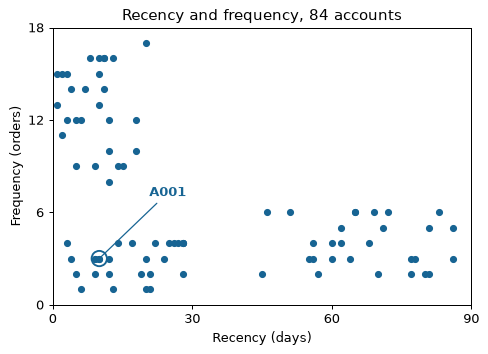

In [15]:
a = rfm.set_index("account_id").loc["A001"]

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(rfm["recency_days"], rfm["frequency_orders"], color=POINT, s=22)
ax.scatter(a["recency_days"], a["frequency_orders"], s=150, facecolors="none", edgecolors=POINT, linewidths=1.5)
ax.annotate("A001", (a["recency_days"], a["frequency_orders"]), xytext=(40, 50), textcoords="offset points",
            color=POINT, fontweight="bold", arrowprops=dict(arrowstyle="-", color=POINT))
ax.set_xlim(0, 90); ax.set_ylim(0, 18)
ax.set_xticks([0, 30, 60, 90]); ax.set_yticks([0, 6, 12, 18])
ax.set_xlabel("Recency (days)")
ax.set_ylabel("Frequency (orders)")
ax.set_title("Recency and frequency, 84 accounts")
plt.show()

**Reading the output.** Find A001 by its coordinates: x = 10 days, y = 3 orders. Frequency is a whole
number, so several accounts can sit on the same point. The density you see was produced by the
generator, so it is not an estimate of any real customer population.

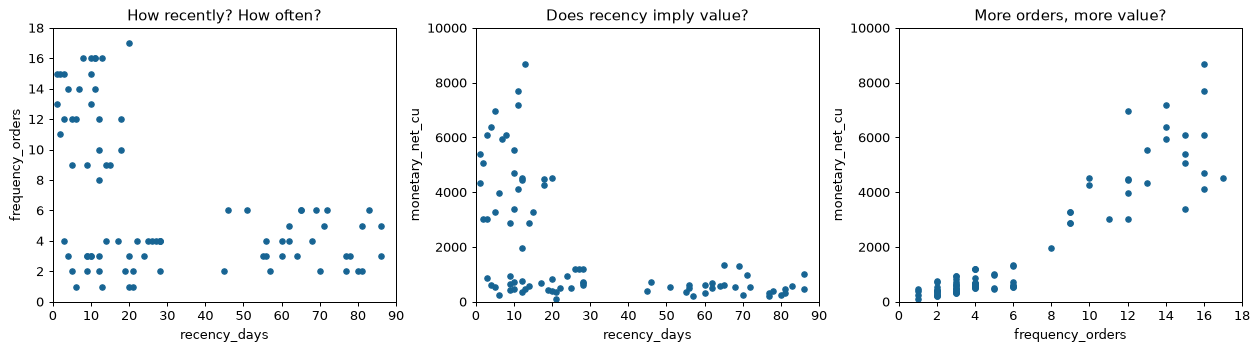

In [16]:
pairs = [("recency_days", "frequency_orders", "How recently? How often?"),
         ("recency_days", "monetary_net_cu", "Does recency imply value?"),
         ("frequency_orders", "monetary_net_cu", "More orders, more value?")]

limits = {"recency_days": (0, 90), "frequency_orders": (0, 18), "monetary_net_cu": (0, 10_000)}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x, y, title) in zip(axes, pairs):
    ax.scatter(rfm[x], rfm[y], color=POINT, s=18)
    ax.set_xlim(limits[x]); ax.set_ylim(limits[y])
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Reading the output.** The same 84 accounts in every panel, three different questions. More orders go
with more net value, but part of that is **built into the definitions**: M is a sum over the orders
counted in F. Which relationships come from the observation process, and which would need more data to
explain? These plots describe; they do not establish causes.

**Check yourself.** Is the F-M relationship a discovery about the accounts?

<details><summary><b>Answer</b></summary>

Mostly not. M sums the values of the same orders that F counts, so more orders almost always mean more
value. A real finding would be something the definitions do not force, for example *value per order*.

</details>

## 7. k-means: assign, move, repeat (slide 11)

**Why.** k-means alternates two steps until the assignments stop changing:

1. **Assign** each point to its nearest centroid.
2. **Move** each centroid to the mean of its assigned points.

Toy 2-D data with k = 2, so one iteration fits on screen.

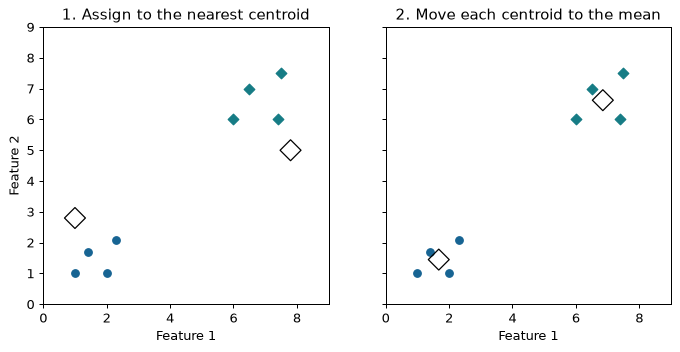

centroids before: [[1.0, 2.8], [7.8, 5.0]]
centroids after : [[1.68, 1.45], [6.85, 6.62]]


In [17]:
toy = np.array([[1.0, 1.0], [1.4, 1.7], [2.0, 1.0], [2.3, 2.1],    # same points as slide 11
                [6.0, 6.0], [6.5, 7.0], [7.4, 6.0], [7.5, 7.5]])
centroids = np.array([[1.0, 2.8], [7.8, 5.0]])                     # starting centroids

# squared distance from every point to every centroid -> index of the nearest one
assign = np.argmin(((toy[:, None, :] - centroids[None]) ** 2).sum(axis=2), axis=1)
moved = np.array([toy[assign == k].mean(axis=0) for k in range(2)])

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, cents, title in [(axes[0], centroids, "1. Assign to the nearest centroid"),
                         (axes[1], moved, "2. Move each centroid to the mean")]:
    for k, name in enumerate(["C1", "C2"]):
        ax.scatter(toy[assign == k, 0], toy[assign == k, 1], color=COLORS[name], marker=MARKERS[name])
    ax.scatter(cents[:, 0], cents[:, 1], marker="D", s=140, facecolors="none", edgecolors="k")
    ax.set_title(title)
    ax.set_xlim(0, 9); ax.set_ylim(0, 9)
    ax.set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
plt.show()
print("centroids before:", centroids.tolist())
print("centroids after :", moved.round(2).tolist())

**Reading the output.** Hollow diamonds are centroids; colors are the assignments. After one move the
centroids sit in the middle of their groups. Repeating the two steps reaches a **local** solution:
different starting centroids can give a different answer, which is why `KMeans` uses `n_init`
restarts. k-means does not tell you the "correct" number of groups.

## 8. Scaling changes what distance means (slide 12)

**Why.** k-means uses Euclidean distance. If one feature is in hundreds of CU and another in a few
orders, the large-unit feature decides everything.

In [18]:
diff_orders, diff_value = 5, 500
print(f"{diff_orders}^2 + {diff_value}^2 = {diff_orders**2 + diff_value**2:,}")
print(f"share of the squared distance from value: {diff_value**2 / (diff_orders**2 + diff_value**2):.4%}")

5^2 + 500^2 = 250,025
share of the squared distance from value: 99.9900%


**Reading the output.** The value difference makes up 99.99% of the distance. A difference of 5 orders
barely counts. Our pipeline, used for the rest of the notebook:

1. Define R, F and net M.
2. Apply `log1p` to each feature (compresses large values; `log1p(x) = log(1 + x)`).
3. Standardize: every feature gets mean 0 and standard deviation 1.
4. Fit k-means with **k = 3**, `n_init=20`, `random_state=42`.

*k = 3 is a demonstration choice, not a discovered business truth* (Homework H3).

In [19]:
if (rfm["monetary_net_cu"] <= 0).any():
    raise ValueError("Nonpositive net M needs a reviewed transformation policy before log1p.")

X = StandardScaler().fit_transform(np.log1p(rfm[RFM_COLS]))
print("scaled feature means:", X.mean(axis=0).round(3), " std:", X.std(axis=0).round(3))

kmeans = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X)

# k-means numbers clusters 0/1/2 arbitrarily. Give them stable display names:
# C1 = highest median net value, then C2 and C3 by ascending median recency.
raw_labels = pd.Series(kmeans.labels_)
medians = rfm.groupby(raw_labels)[RFM_COLS].median()
top = medians["monetary_net_cu"].idxmax()
rest = medians.drop(index=top).sort_values("recency_days").index
names = {k: f"C{i + 1}" for i, k in enumerate([top, *rest])}
rfm["cluster"] = raw_labels.map(names)
rfm["cluster"].value_counts().sort_index()

scaled feature means: [0. 0. 0.]  std: [1. 1. 1.]


cluster
C1    28
C2    22
C3    34
Name: count, dtype: int64

**Reading the output.** Scaled features have mean 0 and standard deviation 1: each has the same
spread, so no feature dominates the distance just because of its units. That changes the *weighting*;
it does not prove that Euclidean distance is the right
business notion of similarity.

Compare with k-means on the **raw** values, where M dominates:

In [20]:
raw_kmeans = KMeans(n_clusters=3, n_init=20, random_state=42).fit(rfm[RFM_COLS])
comparison = rfm.assign(raw_cluster=raw_kmeans.labels_)
print(comparison.groupby("raw_cluster")[RFM_COLS].median())
print()
print(pd.crosstab(comparison["raw_cluster"], comparison["cluster"], colnames=["scaled cluster"]))

             recency_days  frequency_orders  monetary_net_cu
raw_cluster                                                 
0                    28.0               3.0           554.75
1                     7.5              14.5          6235.43
2                    10.0              12.0          4101.54

scaled cluster  C1  C2  C3
raw_cluster               
0                1  22  34
1               10   0   0
2               17   0   0


**Reading the output.** On raw values, k-means spends two of its three groups splitting the
high-value accounts by **M** (thousands of CU apart), and puts all recent low-value (C2) and lapsed (C3)
accounts, plus one C1 account, into one group: a recency gap of about 50 days is tiny next to M. After `log1p` and scaling, recency
counts too, and recent and lapsed accounts are separated. Same data, same algorithm, different units,
different groups.

The guard at the top of the cell stops if any account has zero or negative **net M** (credits larger
than purchases): such accounts need a reviewed policy, not a silent `log`. The model is fit on all 84 accounts because this is **description**, not
prediction. For a predictive model, fit the scaler on training data only.

## 9. Clustering is not projection (slide 13)

**Why.** Two separate tools run on the **same** scaled rows, in the same order:

```
scaled RFM features ──► k-means ──► cluster labels  ─┐
                    └─► t-SNE   ──► 2-D coordinates ─┴─► combined only for display
```

The t-SNE coordinates are **not** the input to k-means. Colors come from the clustering; positions
come from the projection. When colored clusters look well separated on the map, that is a picture,
not proof that the segmentation is valid.

## 10. Same accounts, different t-SNE settings (slide 14)

**Why.** t-SNE places points in 2-D so that accounts that are close in the scaled feature space tend
to stay close. **Perplexity** sets the effective neighborhood size the method tries to preserve. It is
**not** the number of clusters. Below, only perplexity changes (5 vs 25). Seed 42, PCA initialization,
and the cluster colors stay fixed.

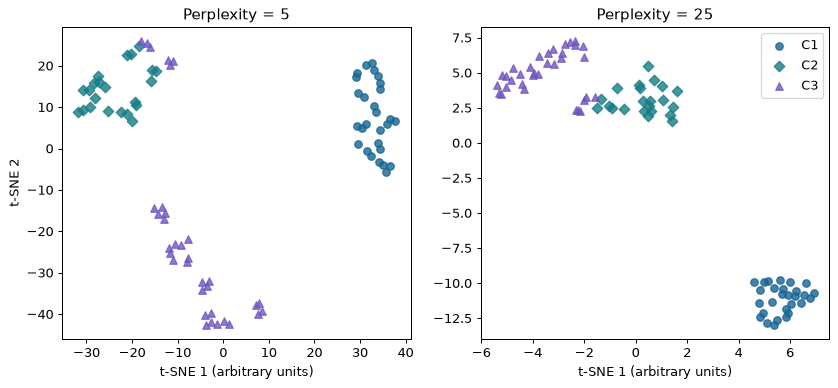

In [21]:
maps = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, perplexity in zip(axes, [5, 25]):
    coords = TSNE(perplexity=perplexity, random_state=42, **TSNE_SETTINGS).fit_transform(X)
    maps[perplexity] = coords
    for name, group in rfm.groupby("cluster"):
        ax.scatter(coords[group.index, 0], coords[group.index, 1],
                   label=name, color=COLORS[name], marker=MARKERS[name], alpha=0.8)
    ax.set_title(f"Perplexity = {perplexity}")
    ax.set_xlabel("t-SNE 1 (arbitrary units)")
axes[0].set_ylabel("t-SNE 2")
axes[1].legend()
plt.show()

**Reading the output.** A different map does **not** mean the accounts changed. Axes are in arbitrary
units, and the two maps are optimized separately, so their distances cannot be compared. Gaps between
groups and the area of a group are not preserved measurements. Discuss the sensitivity, and don't pick
the prettier plot.

**Check yourself.** With perplexity 25 you see C1 far away from one connected arc of C2 and C3.
Does the map support k = 3, or k = 2?

<details><summary><b>Answer</b></summary>

Neither. The colors were assigned by k-means before t-SNE ran, and t-SNE can make groups look
separated, or joined, regardless of the true structure. The picture *suggests* that C2 and C3 are
closer to each other than to C1, but evidence for k comes from the feature space (Homework H3) and from
whether the groups are useful and stable, not from a 2-D picture.

</details>

## 11. Put meaning back on the map (slide 15)

**Why.** A highlighted point should lead back to records you can inspect. Use **one** highlight that
answers a specific question, not color, size, labels and legends all at once.

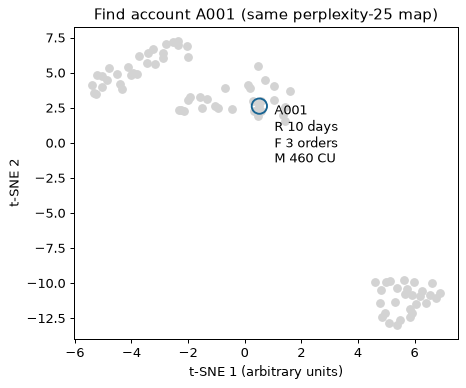

,line_id,account_id,order_id,order_date,product_id,event_type,line_value_cu
0,L0001,A001,O001,2026-01-10,P03,purchase,100.0
1,L0002,A001,O002,2026-02-20,P07,purchase,150.0
2,L0003,A001,O002,2026-02-20,P12,purchase,50.0
3,L0004,A001,O003,2026-03-22,P05,purchase,200.0
4,L0005,A001,C001,2026-03-25,P05,credit,-40.0


In [22]:
coords = maps[25]
i_a001 = rfm.index[rfm["account_id"] == "A001"][0]
r = rfm.loc[i_a001]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(coords[:, 0], coords[:, 1], color="lightgray")
ax.scatter(*coords[i_a001], s=150, facecolors="none", edgecolors=POINT, linewidths=1.5)
ax.annotate(f"A001\nR {r.recency_days} days\nF {r.frequency_orders} orders\nM {r.monetary_net_cu:g} CU",
            coords[i_a001], xytext=(12, -45), textcoords="offset points")
ax.set_title("Find account A001 (same perplexity-25 map)")
ax.set_xlabel("t-SNE 1 (arbitrary units)")
ax.set_ylabel("t-SNE 2")
plt.show()

clean[clean["account_id"] == "A001"]   # trace the point back to its five records

**Reading the output.** The highlighted point is A001, and the table shows the five records behind
it. Its position alone does not say *why* A001 behaves this way. In real tools, hovering over a point
or a linked record table is better than guessing labels.

## 12. Interpret clusters in the feature space (slide 16)

**Why.** Describe each group in **original units** before deciding what action it should trigger.

In [23]:
summary = rfm.groupby("cluster")[RFM_COLS].median()
summary.insert(0, "accounts", rfm["cluster"].value_counts())
summary

,accounts,recency_days,frequency_orders,monetary_net_cu
cluster,,,,
C1,28,10.0,13.0,4491.075
C2,22,12.5,3.0,549.865
C3,34,63.0,4.0,544.895


**Reading the output.** Group sizes add up to 84. This is the slide 16 table: C1 28 / 10.0 / 13 / 4,491,
C2 22 / 12.5 / 3 / 550, C3 34 / 63.0 / 4 / 545 (the slide rounds M to whole CU).

- **C1**: many orders (median 13), high net value, recent.
- **C2**: recent, but few orders and lower value.
- **C3**: last purchase about two months before the snapshot, few orders, lower value.

C1-C3 are **display names**, not ranked value or risk tiers. *C1 has more orders and higher net value
in this window. Why?* That is a new question, not a cluster label. Do not automatically call a group
"loyal" or "at risk". Would the groups survive a different window, weighting or seed? This single run
does not tell us.

## 13. A segment is not a recommendation (slide 17)

**Why.** To recommend something, first define the **candidates**, the **output** and a
**baseline**. Toy catalog with four rows (not from the fixture, and not a clinical recommendation):

In [24]:
catalog = pd.DataFrame({
    "candidate":   ["P01", "P02", "P03", "P04"],
    "past_orders": [14, 9, 4, 2],
    "eligible":    [True, False, True, True],   # P02 is currently unavailable
})

# Popularity baseline: filter to eligible candidates, then rank by observed demand
baseline = catalog[catalog["eligible"]].sort_values("past_orders", ascending=False)
print("popularity baseline:", " -> ".join(baseline["candidate"]))
catalog

popularity baseline: P01 -> P03 -> P04


,candidate,past_orders,eligible
0,P01,14,True
1,P02,9,False
2,P03,4,True
3,P04,2,True


**Reading the output.** P01 → P03 → P04. P02 is popular but unavailable: **availability filters the
candidate set before ranking**. A baseline this simple is what later models must beat.

*Probability? Quantity? Ranked list?* These are different targets:

- **Classification**: probability of an event (will the account order P03?).
- **Regression**: a quantity (how many units?).
- **Ranking**: an ordering of candidates.

A cluster can be a feature or an analysis aid. It is not a recommendation rule by itself.

## 14. Text becomes a table of features (slide 18)

**Why.** A model cannot read text directly. A representation turns it into numbers, and the
representation decides what information the model can use. Bag of words counts each word.

In [25]:
texts = ["cold storage pack", "sterile storage pack"]
vectorizer = CountVectorizer()
counts = vectorizer.fit_transform(texts)

pd.DataFrame(counts.toarray(), columns=vectorizer.get_feature_names_out(), index=["D1", "D2"])

,cold,pack,sterile,storage
D1,1,1,0,1
D2,0,1,1,1


**Reading the output.** The vocabulary is `[cold, pack, sterile, storage]`, computed by
`CountVectorizer`. D1 and D2 share `pack` and `storage`, and differ in `cold` vs `sterile`.
Bag of words **ignores word order** ("pack storage cold" gives the same row). Tokenization, numbers,
unknown words and text length are modeling choices. For a predictive task, fit the vocabulary on
training text only, then transform new text with it.

## 15. Feature engineering: same discipline, different domain (slide 19)

**Why.** Back to real estate, as a transfer example. Features come from three different sources,
and each needs different evidence:

| Kind | Example | Evidence needed |
|---|---|---|
| Observed | area, room count, floor category | correct source and unit |
| Derived | rooms per area | definition, units, edge cases |
| External | neighborhood data | a verified, authorized join (source, rights, key, time) |

In [26]:
props = pd.DataFrame({
    "area_m2": [52.0, 80.0, 0.0, 65.0],     # one record with area 0: a data error, not a tiny flat
    "rooms":   [2, 3, 2, 3],
    "floor_category": ["ground", "middle", "middle", "top"],
})

valid_area = props["area_m2"] > 0
props["rooms_per_10m2"] = np.where(valid_area, props["rooms"] / props["area_m2"] * 10, np.nan)
props["area_check"] = np.where(valid_area, "ok", "zero area: review")
props

,area_m2,rooms,floor_category,rooms_per_10m2,area_check
0,52.0,2,ground,0.384615,ok
1,80.0,3,middle,0.375000,ok
2,0.0,2,middle,NaN,zero area: review
3,65.0,3,top,0.461538,ok


**Reading the output.** The derived feature has a unit (rooms per 10 m²) and an edge case: area 0
would divide by zero. We mark it for review instead of letting `inf` into the data. This feature is an
illustration; we do not claim it improves a model. For **total-price prediction**, the target-derived
`price / surface` from section 3 stays excluded. Use the same feature definitions in training and
in production.

## 16. Embeddings preview: an embedding is learned, not drawn (slides 20-22)

**Why.** An **embedding** is a vector of numbers learned for each ID. Here:

- A **lookup table** `E` with one 4-number vector per account (84 × 4).
- A **linear decoder** `W, b` that turns a vector back into the account's 3 scaled RFM values.
- Training objective: **reconstruct** each known account's scaled RFM row (mean squared error),
  using plain NumPy gradient descent.

This is the idea behind `torch.nn.Embedding`, written by hand. It only reconstructs accounts we
already know. It does **not** predict future behavior, and its near-zero training error is not
a quality claim.

In [27]:
def train_lookup(seed, scale=0.3, steps=3000, lr=0.05, verbose=False):
    rng = np.random.default_rng(seed)
    E = rng.normal(0, scale, size=(len(X), 4))   # lookup: one learned vector per account
    W = rng.normal(0, 0.1, size=(4, 3))          # linear decoder
    b = np.zeros(3)
    for step in range(steps + 1):
        pred = E @ W + b                 # decode every account's vector
        err = pred - X                   # reconstruction error vs scaled RFM
        grad = 2 * err / err.size        # d(mean squared error) / d(pred)
        gE, gW, gb = grad @ W.T, E.T @ grad, grad.sum(axis=0)
        # Each row of E receives the gradient of only its own account (1/84 of the loss), so its
        # gradient is 84 times smaller than W's. A per-row step size of lr * 84 compensates:
        # every account vector learns as fast as if it were trained on its own.
        E -= lr * len(X) * gE
        W -= lr * gW
        b -= lr * gb
        if verbose and step % 1000 == 0:
            print(f"step {step:4d}   training MSE {np.mean(err ** 2):.6f}")
    return E, W, b

# Seed 93 was picked on purpose so that A001's neighbors match slide 22 (see the note below).
E, W, b = train_lookup(seed=93, verbose=True)
print("\nA001 learned vector:", E[i_a001].round(2))

step    0   training MSE 1.010020
step 1000   training MSE 0.000002
step 2000   training MSE 0.000000
step 3000   training MSE 0.000000

A001 learned vector: [1.11 0.26 0.19 0.89]


**Reading the output.** The error falls to almost zero: 4 numbers per account are more than enough to
store 3. The RFM information is not *discovered* here; it is copied into a new form. A new, unknown
account ID has no row in `E` and would need a designed fallback. The specific numbers in A001's vector
mean nothing on their own: another seed gives other numbers with the same reconstruction quality.
That is why A001's vector here is not the one shown on slide 20.

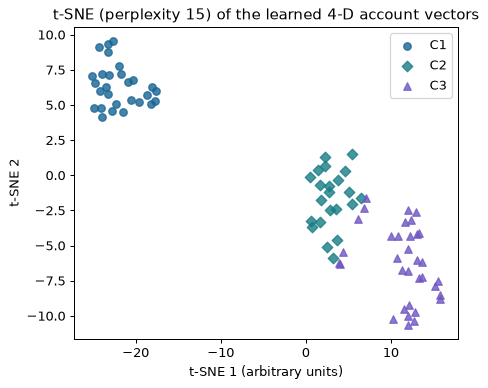

In [28]:
emb_map = TSNE(perplexity=15, random_state=42, **TSNE_SETTINGS).fit_transform(E)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, group in rfm.groupby("cluster"):
    ax.scatter(emb_map[group.index, 0], emb_map[group.index, 1],
               label=name, color=COLORS[name], marker=MARKERS[name], alpha=0.8)
ax.set_title("t-SNE (perplexity 15) of the learned 4-D account vectors")
ax.set_xlabel("t-SNE 1 (arbitrary units)")
ax.set_ylabel("t-SNE 2")
ax.legend()
plt.show()

**Reading the output.** Three different pieces of evidence share this picture: **positions** are a
t-SNE view of the learned 4-D vectors, **colors** are the fixed RFM cluster labels from section 8, and
the **training objective** (reconstruction) decided what the vectors encode.

In [29]:
# Neighbors are measured in the 4-D learned space, not on the 2-D picture.
dist_4d = np.linalg.norm(E - E[i_a001], axis=1)
neighbors = (rfm.assign(distance_4d=dist_4d.round(3))
                .drop(index=i_a001)
                .nsmallest(3, "distance_4d"))
neighbors[["account_id", "distance_4d"] + RFM_COLS]

,account_id,distance_4d,recency_days,frequency_orders,monetary_net_cu
83,A084,0.577,14,4,578.98
70,A071,0.587,9,3,653.88
74,A075,0.730,10,3,708.35


**Reading the output.** A001's three nearest neighbors in the learned 4-D space. Their RFM values are
close to A001's (R = 10 days, F = 3 orders, M = 460 CU), as expected for a reconstruction objective.
These are the same three accounts, in the same order, as on slide 22 (A084, A071, A075), **but only
because we picked the seed for that**: we tried seeds 0-199 and only about 1-2% of them give this
order. The distances also differ from the slide's (0.215 / 0.251 / 0.289), in size and in ratio.

Why so fragile? This objective does not pin down the geometry of `E`:

- **Scale and shape are not identified.** For any invertible 4 × 4 matrix `A`, the pair `E @ A` and
  `inv(A) @ W` gives exactly the same reconstruction (for example `E / 2` with `W * 2`).
- **One direction is never trained.** `E` has 4 columns but only 3 targets, so one direction of `E`
  (the null space of `W`) gets no gradient and keeps its random starting values. Part of every 4-D
  distance is untrained noise.

So compare distances only within one trained table, never across trainings, and do not read meaning
into one seed's neighbors. The next cell shows other seeds.

In [30]:
for seed in [0, 1, 2, 93]:
    E_s, _, _ = train_lookup(seed)
    d = np.linalg.norm(E_s - E_s[i_a001], axis=1)
    d[i_a001] = np.inf
    print(f"seed {seed:3d}: A001's 3 nearest =", list(rfm.loc[np.argsort(d)[:3], "account_id"]))

seed   0: A001's 3 nearest = ['A079', 'A071', 'A084']
seed   1: A001's 3 nearest = ['A071', 'A075', 'A079']
seed   2: A001's 3 nearest = ['A079', 'A084', 'A063']


seed  93: A001's 3 nearest = ['A084', 'A071', 'A075']


**Reading the output.** Every seed reconstructs the RFM table equally well, yet the neighbor lists
differ. A001's neighbors are always accounts with similar R, F and M, but which ones come first depends
on the seed. *Near on a 2-D picture is not a guarantee of near in 4-D* (Homework H5), and near in one
training run is not a guarantee of near in another. A different objective, for example predicting next
purchases, could give a very different geometry.

## Takeaways: leave with three checks (slide 24)

1. **Does the feature mean what we think?** Check the source, unit, population and time window.
2. **Does the plot show what we claim?** Check labels, transformations and projection limits.
3. **What evidence would change our decision?** Separate an observation from a hypothesis or an action.

The slide 23 practice ("one finding, one limit") is homework task **H6** below.

*Next, in Lecture 03: baseline models, fixed evaluation and search.*

---
# Homework

Work in the empty cells below each task. Run the whole walkthrough first, then use what it built:

| Name | Content |
|---|---|
| `raw`, `clean`, `quarantine` | raw rows, cleaned rows, quarantined rows (section 2) |
| `in_window`, `purchases` | clean rows in the window; purchase lines only (section 5) |
| `rfm` | one row per account: R, F, M and `cluster` (sections 5, 8) |
| `X` | scaled log-RFM features, same row order as `rfm` (section 8) |
| `E` | learned 4-D account vectors (section 16) |
| `emb_map` | 2-D t-SNE map of `E` (section 16) |
| `i_a001` | row index of A001 in `rfm`, `X`, `E` |
| `WINDOW_START`, `SNAPSHOT`, `RFM_COLS`, `COLORS`, `MARKERS`, `TSNE_SETTINGS` | settings from the first code cell |

For each task, write a short answer in the text cell. **Explain your choices.** A correct number with no
reasoning is not an answer. Compare with `practice_solution.ipynb` only after you have tried.

Submit the completed notebook as instructed by the course team.

## H1. Data quality: review the credits (slides 3-4)

List every **credit** line in `clean`. For each account with a credit, compute the credit as a
percentage of that account's **gross** purchases (purchases only, before credits).

Also check whether the credit's `product_id` is a product the account actually **bought** in the window.

1. Which credits, if any, would you question, and why?
2. What information is **missing** from this dataset to decide whether a credit is correct?

In [31]:
credits = clean[clean["event_type"] == "credit"]
gross = purchases.groupby("account_id")["line_value_cu"].sum().rename("gross_purchases_cu")
first_purchase = purchases.groupby("account_id")["order_date"].min().rename("first_purchase")

# first date each account bought each product
product_first = (purchases.groupby(["account_id", "product_id"])["order_date"].min()
                 .rename("product_first_bought"))

review = (credits[["account_id", "order_id", "order_date", "product_id", "line_value_cu"]]
          .merge(product_first, on=["account_id", "product_id"], how="left")
          .set_index("account_id").join(gross).join(first_purchase))
review["credit_pct_of_gross"] = (-review["line_value_cu"] / review["gross_purchases_cu"] * 100).round(1)
review["after_first_purchase"] = review["order_date"] > review["first_purchase"]
review["product_was_bought"] = review["product_first_bought"].notna()
review["after_product_bought"] = review["order_date"] > review["product_first_bought"]

print(f"{len(review)} credits; largest share {review['credit_pct_of_gross'].max()}% of gross purchases")
print("all credits after the account's first purchase:", review["after_first_purchase"].all())
print("credits for a product the account did not buy in the window:", (~review["product_was_bought"]).sum())
matched = review[review["product_was_bought"]]
print("credits dated before the credited product was first bought:", (~matched["after_product_bought"]).sum())
review.sort_values(["product_was_bought", "credit_pct_of_gross"], ascending=[True, False])

17 credits; largest share 8.0% of gross purchases
all credits after the account's first purchase: True
credits for a product the account did not buy in the window: 4
credits dated before the credited product was first bought: 0


,order_id,order_date,product_id,line_value_cu,product_first_bought,gross_purchases_cu,first_purchase,credit_pct_of_gross,after_first_purchase,product_was_bought,after_product_bought
account_id,,,,,,,,,,,
A009,C003,2026-03-08,P08,-159.94,NaT,3044.50,2026-01-13,5.3,True,False,False
A060,C010,2026-03-28,P06,-22.68,NaT,514.51,2026-01-16,4.4,True,False,False
A017,C004,2026-03-15,P14,-217.06,NaT,6177.95,2026-01-07,3.5,True,False,False
A079,C016,2026-02-07,P15,-12.95,NaT,375.42,2026-02-06,3.4,True,False,False
A001,C001,2026-03-25,P05,-40.00,2026-03-22,500.00,2026-01-10,8.0,True,True,True
A083,C017,2026-02-28,P01,-74.53,2026-01-08,1007.51,2026-01-08,7.4,True,True,True
A064,C012,2026-03-14,P15,-7.56,2026-03-11,106.00,2026-03-11,7.1,True,True,True
A033,C005,2026-02-05,P18,-71.15,2026-01-20,1035.99,2026-01-02,6.9,True,True,True
A043,C006,2026-03-21,P12,-17.96,2026-01-03,264.98,2026-01-03,6.8,True,True,True


**Answer.**

1. All 17 credits are small (at most 8% of the account's gross purchases) and dated after the account's
   first purchase. The 13 credits for a product the account bought are all dated *after* that product
   was first bought, so they are consistent. But **4 of 17** (A009, A017, A060, A079) name a product the
   account did not buy in the window. A001's credit is for P05, the product of its order O003, so it
   looks consistent. The 4 others could be credits for purchases made before 1 Jan, general discounts
   booked on one product, or errors.
   I would keep them in M (they are documented), list them, and ask the data owner. I would not drop them.
2. A credit names a product, but not the **order or line** it corrects, and has no reason code
   (return, discount, price correction). Without those we cannot match a credit to a specific purchase.
   This is a limit of the data, not something we can fix by cleaning.

## H2. Window sensitivity: same formula, different window (slides 7-8)

Recompute RFM with the window **1 Feb - 31 Mar 2026** (same snapshot, 1 Apr). Use the same
definitions as section 5.

1. How many accounts are in the new population? Why is it not 84?
2. For accounts in both tables, how many change R, F or M? Why does R behave differently from F and M?
3. In one sentence: why can F and M change when the formula did not?

In [32]:
FEB_START = pd.Timestamp("2026-02-01")
feb = clean[(clean["order_date"] >= FEB_START) & (clean["order_date"] < SNAPSHOT)]
feb_purchases = feb[feb["event_type"] == "purchase"]
rfm_feb = pd.DataFrame({
    "recency_days":     (SNAPSHOT - feb_purchases.groupby("account_id")["order_date"].max()).dt.days,
    "frequency_orders": feb_purchases.groupby("account_id")["order_id"].nunique(),
    "monetary_net_cu":  feb.groupby("account_id")["line_value_cu"].sum().round(2),
})

# Population policy (same as section 5): an account needs at least one purchase in the window.
# Accounts with only a credit in Feb-Mar would get no R and a negative M, so we list and exclude them.
credit_only = rfm_feb[rfm_feb["recency_days"].isna()]
print("credit-only accounts in Feb-Mar (excluded):")
print(credit_only[["monetary_net_cu"]].T)
rfm_feb = rfm_feb.dropna(subset=["recency_days"])

both = rfm.set_index("account_id")[RFM_COLS].join(rfm_feb, rsuffix="_feb", how="inner")
dropped = sorted(set(rfm["account_id"]) - set(rfm_feb.index))
print("\naccounts in the Feb-Mar population:", len(rfm_feb))
print("accounts with no purchase in Feb-Mar:", dropped)
for col in RFM_COLS:
    print(f"{col:17s} changed for {(both[col] != both[col + '_feb']).sum():2d} of {len(both)} accounts")
both.loc[["A001", "A010", "A070"]]

credit-only accounts in Feb-Mar (excluded):
account_id        A033   A043   A054  A055
monetary_net_cu -71.15 -17.96 -20.98 -29.3

accounts in the Feb-Mar population: 63
accounts with no purchase in Feb-Mar: ['A030', 'A031', 'A032', 'A033', 'A034', 'A035', 'A037', 'A038', 'A039', 'A040', 'A043', 'A044', 'A046', 'A049', 'A051', 'A052', 'A053', 'A054', 'A055', 'A056', 'A057']
recency_days      changed for  0 of 63 accounts
frequency_orders  changed for 53 of 63 accounts
monetary_net_cu   changed for 53 of 63 accounts


,recency_days,frequency_orders,monetary_net_cu,recency_days_feb,frequency_orders_feb,monetary_net_cu_feb
account_id,,,,,,
A001,10,3,460.00,10.0,2.0,360.00
A010,12,12,4437.33,12.0,7.0,2718.20
A070,28,4,599.07,28.0,2.0,364.96


**Answer.**

1. 63 accounts. The 21 accounts whose purchases were all in January (for example A040) have no purchase
   in the new window, so they leave the population. Four of them (A033, A043, A054, A055) still
   have a **credit** in Feb-Mar: they would have no R and a negative M, so the population policy
   (at least one purchase in the window) excludes them, and we list them instead of dropping them
   silently. Note A055: its row dated `2026-02-30` was quarantined in section 2. If the data owner
   confirms it was a February purchase, A055 comes **back** into this population. Cleaning decisions
   change who is counted. The population depends on the window, and so does every summary statistic.
2. R changes for **none** of the 63 accounts: if an account has any purchase in Feb-Mar, its *last*
   purchase is in Feb-Mar in both windows, and the snapshot is the same. F and M change for 53 accounts,
   because their January orders and credits are no longer counted (A070: F 4 → 2, M 599.07 → 364.96 CU).
   Watch out: a credit can stay in the window while the purchase it corrects drops out.
3. F and M are sums over a period, so changing the period changes the sums. F can only go down when
   the window shrinks. Net M usually goes down too, but in general it can go **up** if a January credit
   drops out (no account here has that case).
   A feature is the formula *plus* its window, and both must be reported.

## H3. Choice of k (slide 12)

Fit k-means on `X` for k = 2, 3, 4, 5, 6 (same `n_init=20`, `random_state=42`).
Plot two measures against k:

- **Inertia** (`model.inertia_`): the sum of squared distances from each point to its centroid.
  Lower means tighter groups.
- **Silhouette score** (`sklearn.metrics.silhouette_score(X, model.labels_)`): for each point, how much
  closer it is to its own group than to the nearest other group, averaged; from −1 to 1, higher means
  better separated.

1. What happens to inertia as k grows? Why can't you choose k by minimizing it?
2. Which k has the best silhouette? Does that make it the "true" number of customer types?

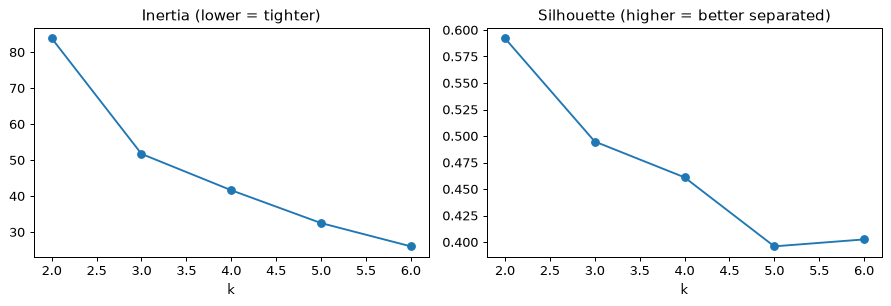

,k,inertia,silhouette
0,2,83.9,0.592
1,3,51.7,0.495
2,4,41.6,0.461
3,5,32.5,0.396
4,6,26.0,0.403


In [33]:
from sklearn.metrics import silhouette_score

ks = range(2, 7)
inertia, silhouette = [], []
for k in ks:
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(ks, inertia, marker="o"); axes[0].set_title("Inertia (lower = tighter)"); axes[0].set_xlabel("k")
axes[1].plot(ks, silhouette, marker="o"); axes[1].set_title("Silhouette (higher = better separated)"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(silhouette, 3)})

**Answer.**

1. Inertia generally goes down as k grows: more centroids means every point can be closer to one.
   (k-means finds a local solution, so a small bump is possible, but the trend is down.) With k = 84
   it is zero, because all 84 accounts are distinct points. Minimizing inertia would always choose the largest k.
2. Here the silhouette is best at **k = 2** (about 0.59), not at the k = 3 used in the lecture (about
   0.50). With k = 2, the frequent high-value accounts (C1) form one group and everyone else the other.
   This is exactly why slide 12 calls k = 3 *a demonstration choice, not a discovered business truth*:
   no single metric decides k. The silhouette is one piece of evidence; choosing k also depends on
   whether the groups are stable (other seeds and windows) and **useful** for a decision. A third group
   that separates recent from lapsed accounts may be worth more than a better silhouette.

## H4. t-SNE sensitivity (slide 14)

Make a 2 × 4 grid of t-SNE maps of `X`: perplexity 5, 15, 25, 40 (columns) and `random_state` 0 and 42
(rows). Keep the cluster colors fixed.

Use `TSNE_SETTINGS` but with **`init="random"`**: with `init="pca"` (used above) the starting layout comes
from PCA, which does not depend on the seed, so the seed has almost no visible effect. Random
initialization shows how much the seed alone can change a map.

1. What changes between the maps? What stays the same?
2. Which conclusions about the accounts are safe to draw from these maps, and which are not?

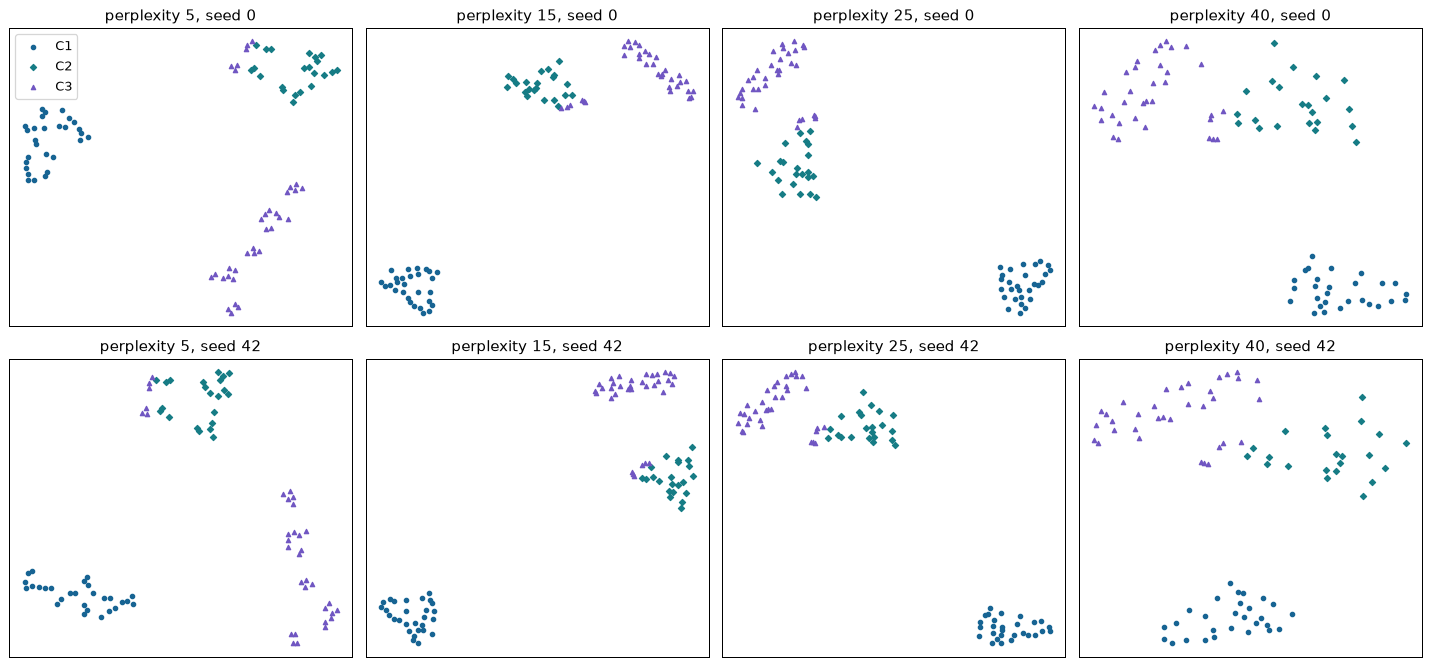

In [34]:
perplexities, seeds = [5, 15, 25, 40], [0, 42]
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for row, seed in enumerate(seeds):
    for col, perplexity in enumerate(perplexities):
        settings = {**TSNE_SETTINGS, "init": "random"}
        coords = TSNE(perplexity=perplexity, random_state=seed, **settings).fit_transform(X)
        ax = axes[row, col]
        for name, group in rfm.groupby("cluster"):
            ax.scatter(coords[group.index, 0], coords[group.index, 1], s=12, color=COLORS[name], marker=MARKERS[name], label=name)
        ax.set_title(f"perplexity {perplexity}, seed {seed}")
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].legend()
plt.tight_layout(); plt.show()

**Answer.**

1. **Seed** (rows): with random initialization, the same perplexity gives a different placement and
   orientation. **Perplexity** (columns): at 5, the map breaks into several small clumps (very local
   structure), and some C3 triangles sit right next to C2 diamonds; at 25-40 the groups become smoother
   and C1 sits far from the rest. The gaps between groups and their apparent sizes change in every panel.
   The accounts, their features and their colors do not change.
2. Safe: "C1 accounts appear together, apart from the others, in every setting" (a weak hint that C1
   is compact and separated in feature space), and "C2 and C3 sometimes mix" (a hint that the boundary
   between recent and lapsed low-value accounts is less clear). Not safe: comparing distances between groups, group sizes or
   areas, or counting clusters from the picture. Check those in the feature space, not on the map.

## H5. Embedding neighbors: 4-D vs 2-D (slide 22)

For A001, find the 5 nearest accounts in **three** spaces:

- the scaled RFM features `X` (3-D),
- the learned vectors `E` (4-D),
- the t-SNE map of `E` (`emb_map`, 2-D).

How many neighbors do the lists share? Explain why the 2-D list can disagree with the 4-D list.

In [35]:
def nearest(space, i, n=5):
    d = np.linalg.norm(space - space[i], axis=1)
    d[i] = np.inf
    return list(rfm.loc[np.argsort(d)[:n], "account_id"])

lists = {"scaled RFM (3-D)": nearest(X, i_a001),
         "learned E (4-D)": nearest(E, i_a001),
         "t-SNE of E (2-D)": nearest(emb_map, i_a001)}
for name, ids in lists.items():
    print(f"{name:18s} {ids}")
print("shared by 3-D and 4-D:", len(set(lists["scaled RFM (3-D)"]) & set(lists["learned E (4-D)"])))
print("shared by 4-D and 2-D:", len(set(lists["learned E (4-D)"]) & set(lists["t-SNE of E (2-D)"])))

scaled RFM (3-D)   ['A079', 'A071', 'A075', 'A063', 'A084']
learned E (4-D)    ['A084', 'A071', 'A075', 'A061', 'A079']
t-SNE of E (2-D)   ['A079', 'A071', 'A075', 'A084', 'A059']
shared by 3-D and 4-D: 4
shared by 4-D and 2-D: 4


**Answer.**

In this run the 3-D and 4-D lists share 4 of 5 accounts, but in a different order: A084 is A001's
nearest neighbor in the learned 4-D space, yet only 5th in the scaled RFM features, and A079 is nearest
in the RFM features but 5th in 4-D. The vectors were trained to reconstruct the scaled RFM, so they keep
most of its neighborhoods, not all of them. The 2-D t-SNE list shares 4 of 5 with the 4-D list, and
puts A079 first again. Squeezing 4 dimensions into 2 must distort some distances, and t-SNE
optimizes neighbor probabilities, not exact distances. Check neighbors in the representation itself,
then confirm them in the records (the RFM values).

## H6. One finding, one limit (slide 23)

1. **Define**: choose one feature (new or from above). State its unit and observation window.
2. **Inspect**: make **one** plot. Point to the data behind your finding.
3. **Limit**: state one claim your evidence does **not** establish.

*Example limit: recent purchases do not, on their own, establish customer loyalty.*

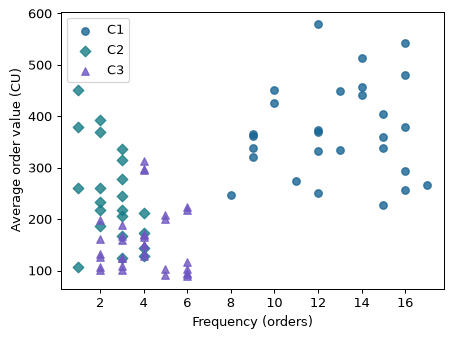

         count    min    50%    max
cluster                            
C1        28.0  227.0  364.0  579.0
C2        22.0  106.0  226.0  451.0
C3        34.0   89.0  142.0  313.0


In [36]:
# 1. Define: "average order value" (AOV) = gross purchase value / number of purchase orders.
#    Unit: CU per order. Window: 1 Jan - 31 Mar 2026. Credits excluded (they are not orders).
gross_value = purchases.groupby("account_id")["line_value_cu"].sum()
aov = (gross_value / purchases.groupby("account_id")["order_id"].nunique()).rename("aov_cu")
rfm_h6 = rfm.join(aov, on="account_id")

# 2. Inspect: do frequent accounts only order more often, or also order more per order?
fig, ax = plt.subplots(figsize=(5.5, 4))
for name, group in rfm_h6.groupby("cluster"):
    ax.scatter(group["frequency_orders"], group["aov_cu"], color=COLORS[name], marker=MARKERS[name],
               label=name, alpha=0.8)
ax.set_xlabel("Frequency (orders)"); ax.set_ylabel("Average order value (CU)"); ax.legend()
plt.show()
print(rfm_h6.groupby("cluster")["aov_cu"].describe()[["count", "min", "50%", "max"]].round(0))

**Answer.**

- **Feature.** Average order value (AOV): gross purchase value divided by the number of purchase
  orders, in CU per order, over 1 Jan - 31 Mar 2026. Unlike "March share", it is not fixed by the
  definition of R, so it can show something R, F and M do not show directly.
- **Finding.** C1 accounts do not only order more often; they also order more **per order**: median
  AOV is about 364 CU for C1, 226 CU for C2 and 142 CU for C3. C2 and C3 have almost the same net M
  (about 550 CU), but C2 reaches it with fewer, larger orders. The ranges overlap (C1 227-579,
  C2 106-451, C3 89-313 CU), so this describes the groups, not every account.
- **Limit.** AOV for C2 and C3 rests on only 1-6 orders per account, so single orders move it a lot.
  It does not show that C1 accounts are bigger businesses, more profitable (we have no costs or
  margins) or more loyal, and it says nothing about what they will order next quarter.